# Machine Learning Project

## Miopia Dataset

We start by importing the dependencies for the project and analyzing the data

In this cell we load all the libraries we use in the first part (pandas, numpy, matplotlib, xgboost and scikit-learn).

We also read the three files of the project:
- `X_t`: the features of the 132 training students (49 columns).
- `Y_t`: the 4 labels of the same students (M, MM, Combo, DCombo).
- `X_test`: the features of the 24 test students. This file has no labels, we must predict them.

In [230]:
import time
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from xgboost import XGBClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score, f1_score,
                             roc_curve, precision_recall_curve, confusion_matrix)

X_t = pd.read_csv("data/X_train.csv")
Y_t = pd.read_csv("data/Y_train.csv")
X_test = pd.read_csv("data/X_test.csv")

We now see the variables in the dataset

In [231]:
X_t.head()

,fecha,edad,sexo,origen antepasados (españa),origen antepasados (extranjeros),hº deporte sem,hº naturaleza sem,hº ocio exteriores sem,horas exterior sem,hº estudiar sem,...,OS-DS,CUVAF-Total,CUVAF-Media,CUVAF-DS,Promedio Nasal,DE Nasal,Suma Nasal,Promedio Temporal,DE Temporal,Suma Temporal
0,2/11/20,22,Mujer,Asturias,NaN,0.0,0.0,4.0,4.0,40,...,0.238059,2.256667,0.564167,0.842300,0.905000,1.279863,1.810000,0.223333,0.160278,0.446667
1,2/17/20,23,Mujer,Navarra,NaN,5.0,2.0,2.0,9.0,20,...,2.585654,8.026667,2.006667,1.887316,3.620833,0.503224,7.241667,0.392500,0.102530,0.785000
2,3/10/20,22,Mujer,Bizkaia,NaN,2.0,3.0,8.0,13.0,30,...,0.431335,12.710000,3.177500,0.743668,3.152500,1.248043,6.305000,3.202500,0.314663,6.405000
3,2/26/20,22,Mujer,"Navarra, Extremadura, Cataluña, Aragón",España,0.0,2.0,13.0,15.0,54,...,0.626968,3.551667,0.887917,0.877145,1.003333,1.418928,2.006667,0.772500,0.491439,1.545000
4,2/19/20,23,Mujer,Toledo,NaN,3.0,0.0,0.0,3.0,56,...,1.269257,1.795000,0.448750,0.897500,0.897500,1.269257,1.795000,0.000000,0.000000,0.000000


`Y_t` has one row per student and one column per task. M and MM are SI/NO, Combo is C/M/MM and DCombo is C/M1/M2/MM.

In [232]:
Y_t.head()

,M,MM,Combo,DCombo
0,SI,SI,MM,MM
1,SI,NO,M,M1
2,NO,NO,C,C
3,NO,NO,C,C
4,NO,NO,C,C


Here we print the name of all the columns of `X_t`. There are many types of information: age and sex, hours of activities per week, family history, sun habits, the CUVAF measures and the biometry of the eye (axial length `LA` and keratometry `Querato`).

In [233]:
list(X_t.columns)

['fecha',
 'edad',
 'sexo',
 'origen antepasados (españa)',
 'origen antepasados (extranjeros)',
 'hº deporte sem',
 'hº naturaleza sem',
 'hº ocio exteriores sem',
 'horas exterior sem',
 'hº estudiar sem',
 'hº ocio inter sem',
 'hº act.cerca sem',
 'horas interior sem',
 'Ratio Cerca/Lejos',
 'Exterior Mucho',
 'Interior Mcho',
 'fototipo',
 'Grupo fot',
 'familiar miope',
 'Familiar miope num.',
 'Familiar MM SI/NO',
 'familiar miope magno',
 'pat. Ret. Miop magna',
 'fumador',
 'toma sol',
 'protege sol',
 'disp.elec.antes dormir',
 'LA OD',
 'LA OS',
 'LA Media',
 'Querato OD',
 'Querato OD Eje2',
 'Querato OS',
 'Querato OS Eje 2',
 'OD-Total',
 'OD-Media',
 'OD-DS',
 'OS-Total',
 'OS-Media',
 'OS-DS',
 'CUVAF-Total',
 'CUVAF-Media',
 'CUVAF-DS',
 'Promedio Nasal',
 'DE Nasal',
 'Suma Nasal',
 'Promedio Temporal',
 'DE Temporal',
 'Suma Temporal']

We start by seeing that in the X_train part of the data there are some columns which can be dropped, since they can be considered redundant for the analysis we want to make.

First, the 'fecha' column is the date of the test. As this is a tracking value for the test itself it doesn't influence in the data and could even lead to some false correlations

We now try to see if we can discard some of the other columns

We look at the column `hº act.cerca sem` (hours of near activity per week).

In [234]:
X_t['hº act.cerca sem'].head()


0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
Name: hº act.cerca sem, dtype: float64

The output shows only NaN. In fact this column is empty for **all** the students (100% missing, also in the test set), so we can not use it.

In the next cell we separate the numeric columns in two groups. If a column has more than 5 different values we say it is "continuous" (`cont_cols`). We use this list later for the correlation plot.

In [235]:
num_cols = X_t.select_dtypes('number').columns.tolist()
cont_cols = [c for c in num_cols if X_t[c].nunique() > 5]          # continuous-like

Now we look at the four targets. For every target we make a bar plot with the number of students in each class.

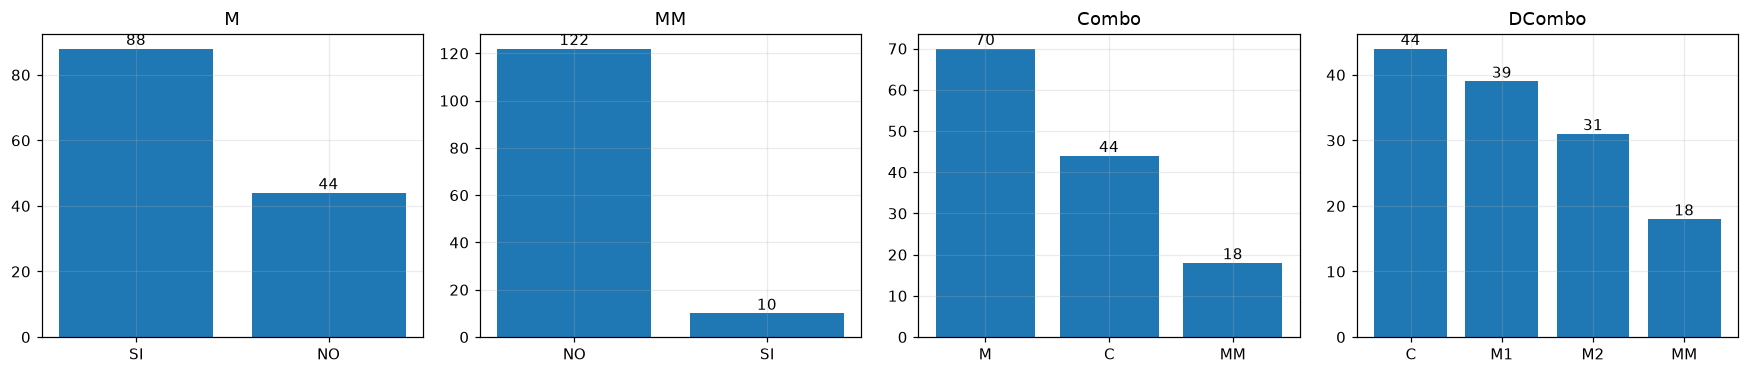

In [236]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, Y_t.columns):
    vc = Y_t[col].value_counts()
    ax.bar(vc.index.astype(str), vc.values)
    for i, v in enumerate(vc.values):
        ax.text(i, v, v, ha='center', va='bottom')
    ax.set_title(col)
plt.tight_layout()
plt.show()

We see that the data for MM is skewed since there are a lot more negatives than positives

The numbers are:
- M: 88 SI and 44 NO.
- MM: only 10 SI and 122 NO. This is very unbalanced, a model that always says NO is already right 92% of the time.
- Combo: 70 M, 44 C and 18 MM.
- DCombo: 44 C, 39 M1, 31 M2 and 18 MM.

Because of this, later all the models use `class_weight='balanced'` (or sample weights for XGBoost), so the errors on the small class cost more. We also use balanced accuracy and not normal accuracy.

In the next cell we make cross tables between the targets, to see how they are connected.

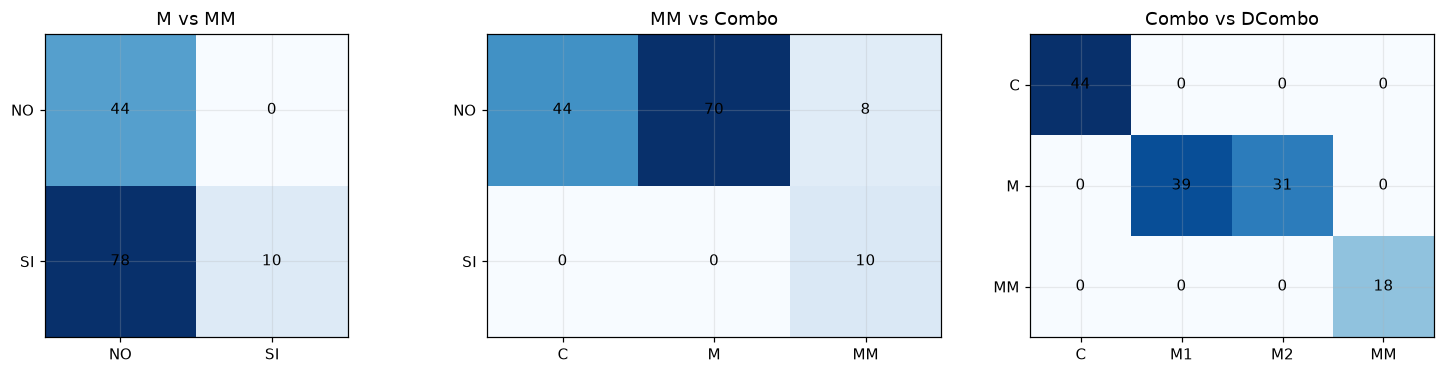

In [237]:
def heat(ct, ax, title):
    ax.imshow(ct.values, cmap='Blues')
    ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns)
    ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            ax.text(j, i, ct.values[i, j], ha='center', va='center')
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
heat(pd.crosstab(Y_t['M'], Y_t['MM']), axes[0], 'M vs MM')
heat(pd.crosstab(Y_t['MM'], Y_t['Combo']), axes[1], 'MM vs Combo')
heat(pd.crosstab(Y_t['Combo'], Y_t['DCombo']), axes[2], 'Combo vs DCombo')
plt.tight_layout()
plt.show()

The cross tables show that the targets are nested:
- All the students with M = NO are C in Combo, and all with M = SI are M or MM.
- All the students with MM = SI are MM in Combo. But Combo MM has 18 students and MM = SI only 10, so 8 students are MM in Combo for another reason (we find the reason below).
- DCombo is the same as Combo, but the M class is split in M1 and M2.

So the four tasks are not independent, and the predictions should agree with each other.

Now we compute the percentage of missing values for each column and we plot only the columns that have some missing value.

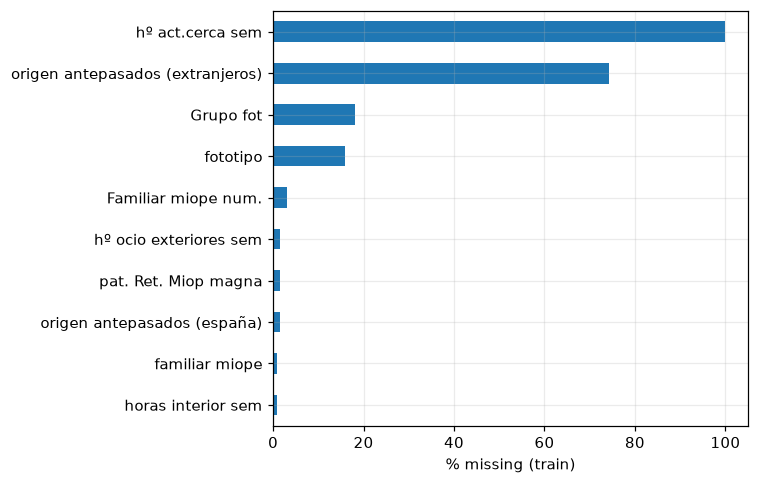

In [238]:
miss = (X_t.isna().mean() * 100).sort_values()
miss = miss[miss > 0]
ax = miss.plot.barh(figsize=(7, 0.35 * len(miss) + 1))
ax.set_xlabel('% missing (train)')
plt.tight_layout()
plt.show()

We note down that a lot of the data in columns origen antepasados (extranjeros), grupos fot and fototipo is missing.

From the plot:
- `hº act.cerca sem` is 100% missing.
- `origen antepasados (extranjeros)` is around 74% missing.
- `Grupo fot` (18%) and `fototipo` (16%) also have many holes.
- All the other columns have less than 3% missing. For them we fill the holes with the median, inside the pipeline of each model.

In the next cell we compute the Spearman correlation between the continuous columns. Spearman works with the ranks of the values, so it also finds relations that are not linear. We also reorder the columns with hierarchical clustering: columns that are very similar are put next to each other, and in the plot we can see them as red or blue blocks.

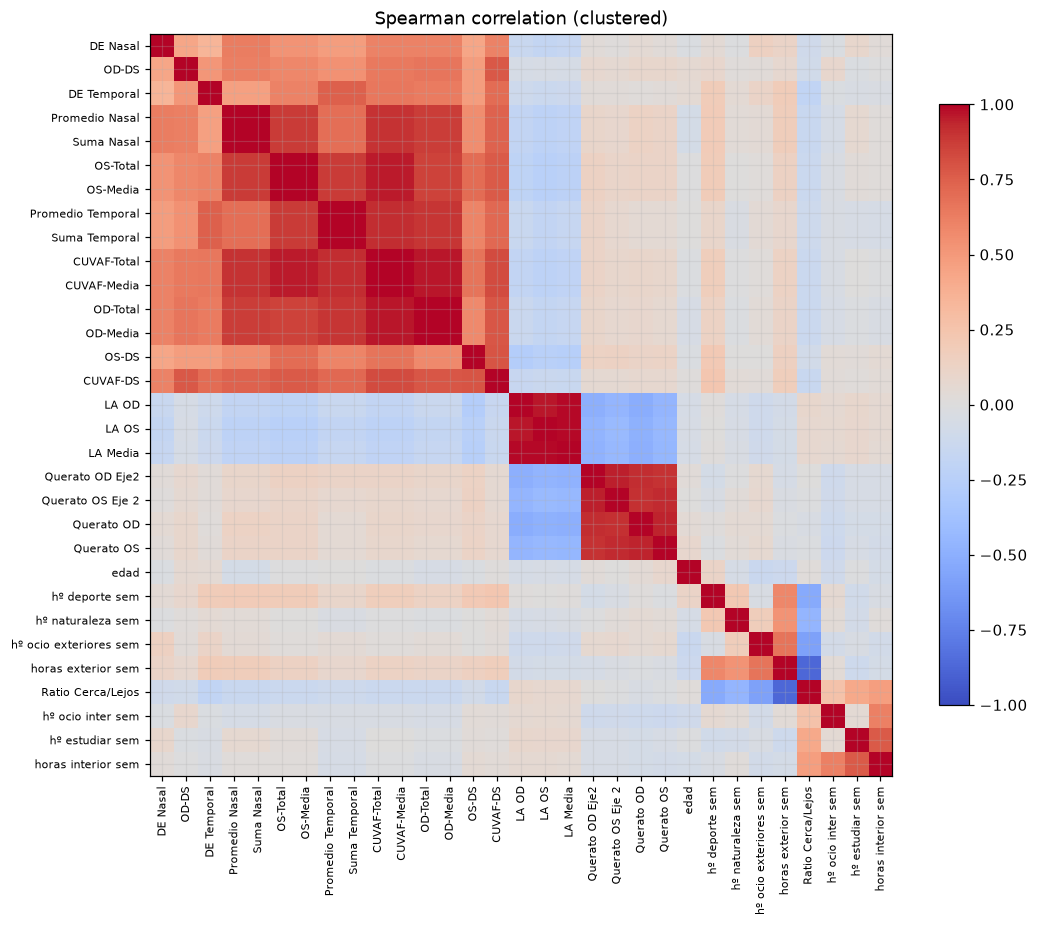

In [239]:
corr = X_t[cont_cols].corr(method='spearman')
d = (1 - corr.abs()).fillna(1).to_numpy(copy=True)   # writable copy
np.fill_diagonal(d, 0)
d = (d + d.T) / 2
order = leaves_list(linkage(squareform(d, checks=False), 'average'))
corr = corr.iloc[order, order]

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.7)
ax.set_title('Spearman correlation (clustered)')
plt.tight_layout()
plt.show()

Furthermore we find that the group of columns most correlated between them can also be grouped since we researched the data behind a CUVAF study. We now run the following analysis to see the difference between the columns and see if they can be aggregated into one. With this we see that CUVAF Total and CUVAF Media are the result of operating on the information in the other columns, which also happens with horas interior semana

In [240]:
rule = (Y_t['MM'] == 'SI') | (X_t[['LA OD', 'LA OS']].max(axis=1) > 26)
print('Combo MM == (MM dioptres OR axial length > 26 mm):', ((Y_t['Combo'] == 'MM') == rule).all())

def maxdiff(a, b): return float((a - b).abs().max())   # NaN-safe; ~0 means identical
print(maxdiff(X_t['CUVAF-Total'], X_t['OD-Total'] + X_t['OS-Total']))
print(maxdiff(X_t['CUVAF-Total'], X_t['Suma Nasal'] + X_t['Suma Temporal']))
print(maxdiff(X_t['CUVAF-Media'], X_t['CUVAF-Total'] / 4))
print(maxdiff(X_t['horas interior sem'], X_t['hº estudiar sem'] + X_t['hº ocio inter sem']))
print(pd.crosstab(X_t[['LA OD', 'LA OS']].max(axis=1) > 26, Y_t['Combo']))

Combo MM == (MM dioptres OR axial length > 26 mm): True
2.999999537678377e-08
4.000000330961484e-08
5.000000413701855e-09
0.0
Combo   C   M  MM
row_0            
False  44  70   3
True    0   0  15


Results of the cell above:
- The first line prints `True`. This means that the class MM in Combo is exactly: MM by dioptres **or** axial length bigger than 26 mm in one eye. This explains the 8 extra students that we saw before. It also tells us that the axial length (`LA`) will be a very important feature for Combo and DCombo.
- The other numbers are all (almost) 0. So `CUVAF-Total` = `OD-Total` + `OS-Total` = `Suma Nasal` + `Suma Temporal`, `CUVAF-Media` = `CUVAF-Total` / 4 and `horas interior sem` = `hº estudiar sem` + `hº ocio inter sem`. These columns are only copies of other columns, so they give no new information.
- The last table shows Combo against "axial length > 26": all students with long eyes are in MM.

Now we define which columns we want to keep and which we want to merge since they seem to add redundant informaiton.

Furthermore, we also define 3 scenarios to aggregate the variables and train our models. With this we can also analyze which part of the data contribute to the a better result in the learning of the algorithm

`build_features` takes the original table and returns a new, smaller table with only the features we want. We write it as a function because we must apply **exactly the same** steps to the test set later.

What it does:
- `edad` stays the same, `sexo` becomes `mujer` (1 = woman, 0 = man).
- The 5 columns of hours per week stay the same. We don't use the totals (`horas exterior/interior sem`) because they are sums of these.
- `fumador`, `toma sol` and `protege sol` become 0/1.
- `disp.elec.antes dormir` becomes a number in order: Nunca = 0, A veces = 1, Siempre = 2.
- The family column is text like "Padre, Madre". We make three 0/1 columns: `fam_padre`, `fam_madre`, `fam_hermanos`. `Familiar MM SI/NO` becomes two 0/1 columns (`famMM_si` and `famMM_nose`).
- CUVAF: we keep only 5 columns (total, nasal, temporal, OD and OS).
- Biometry: the mean and the max of the axial length of the two eyes (`LA_mean`, `LA_max`), and the mean of the keratometry (`K_mean`).

After that we make three scenarios. Each one adds a group of features to the one before:
- **A**: only lifestyle and family (17 features).
- **B**: A + CUVAF (22 features).
- **C**: B + biometry (25 features).

Comparing A, B and C, we can see how much each group of features helps the models.

In [241]:
def build_features(df):
    G = pd.DataFrame(index=df.index)
    G['edad'] = df['edad']
    G['mujer'] = (df['sexo'] == 'Mujer').astype(int)
    for c in ['hº deporte sem', 'hº naturaleza sem', 'hº ocio exteriores sem', 'hº estudiar sem', 'hº ocio inter sem']:
        G[c] = df[c]
    for new, old in [('fumador', 'fumador'), ('toma_sol', 'toma sol'), ('protege_sol', 'protege sol')]:
        G[new] = (df[old] == 'SI').astype(int)
    G['dispositivo'] = df['disp.elec.antes dormir'].map({'Nunca': 0, 'A veces': 1, 'Siempre': 2})
    G['fam_num'] = df['Familiar miope num.']
    fam = df['familiar miope'].fillna('')
    for k in ['Padre', 'Madre', 'Hermanos']:
        G[f'fam_{k.lower()}'] = fam.str.contains(k).astype(int)
    G['famMM_si'] = (df['Familiar MM SI/NO'] == 'Si').astype(int)
    G['famMM_nose'] = (df['Familiar MM SI/NO'] == 'No lo se').astype(int)
    G['CUVAF_total'] = df['CUVAF-Total']; G['CUVAF_nasal'] = df['Suma Nasal']; G['CUVAF_temporal'] = df['Suma Temporal']
    G['CUVAF_OD'] = df['OD-Total'];       G['CUVAF_OS'] = df['OS-Total']
    G['LA_mean'] = df[['LA OD', 'LA OS']].mean(axis=1)
    G['LA_max'] = df[['LA OD', 'LA OS']].max(axis=1)
    G['K_mean'] = df[['Querato OD', 'Querato OS']].mean(axis=1)
    return G

F = build_features(X_t)

cuvaf = ['CUVAF_total', 'CUVAF_nasal', 'CUVAF_temporal', 'CUVAF_OD', 'CUVAF_OS']
biometry = ['LA_mean', 'LA_max', 'K_mean']
lifestyle = [c for c in F.columns if c not in cuvaf + biometry]

scenarios = {'A_lifestyle': lifestyle,
             'B_+CUVAF': lifestyle + cuvaf,
             'C_+biometry': lifestyle + cuvaf + biometry}

We list the columns in our temporary dataframe F, we see that we have a much lower amount of columns

In [242]:
list(F.columns)

['edad',
 'mujer',
 'hº deporte sem',
 'hº naturaleza sem',
 'hº ocio exteriores sem',
 'hº estudiar sem',
 'hº ocio inter sem',
 'fumador',
 'toma_sol',
 'protege_sol',
 'dispositivo',
 'fam_num',
 'fam_padre',
 'fam_madre',
 'fam_hermanos',
 'famMM_si',
 'famMM_nose',
 'CUVAF_total',
 'CUVAF_nasal',
 'CUVAF_temporal',
 'CUVAF_OD',
 'CUVAF_OS',
 'LA_mean',
 'LA_max',
 'K_mean']

From the discussion in class the algorithm that most perked our interest are XGboost and SVM. Since to use these algorithms we need to define their hyperparameters we define the following functions to help better tune these hyperparameters and get a better performance out of our models

The next cell has only definitions, it doesn't train anything yet. There are three tools:

1. **`make_search`** builds a model that can tune itself. For the SVM it tries all the combinations in a grid (`GridSearchCV`). For XGBoost there are too many combinations, so it tries only 12 random ones (`RandomizedSearchCV`). At the end of the notebook we also added Random Forest (`'RF'`) and Logistic Regression (`'LR'`) here, so the four models are tuned in the same way.
2. **`get_scores`** gives one number per student that says "how much this student looks positive". For the SVM it is the distance to the boundary (cut at 0), for the other models it is a probability (cut at 0.5).
3. **`nested_cv`** is the main routine. It gives an honest score for one combination of (task, scenario, model).

Why "nested" cross-validation? We only have 132 students. If we choose the hyperparameters and measure the score on the same students, the score is too optimistic. So we use two loops:
- **Outer loop** (5 folds, repeated): it works like an exam. The model is trained with 4/5 of the students and tested on the other 1/5, which it never saw.
- **Inner loop** (3 folds): inside the training part only, it chooses the best hyperparameters.

For every outer fold we save:
- For M and MM: ROC AUC, PR AUC, balanced accuracy and F1.
- For Combo and DCombo: balanced accuracy and macro F1.

We also save the out-of-fold scores (for ROC curves and confusion matrices), the permutation importance of each feature and the hyperparameters that won.

In [243]:
# =====================================================================================
# TOOL 1: make_search  ->  builds a model that can tune ITSELF (but is NOT trained yet)
# =====================================================================================
def make_search(kind, scoring, inner, seed=0):
    # kind    : 'SVM', 'XGB', 'RF' or 'LR' (which model to build)
    # scoring : the score the tuning tries to maximise (e.g. 'roc_auc')
    # inner   : the inner folds used to test each candidate setting
    # seed    : fixes the randomness so you get the same answer every run

    if kind == 'SVM':
        # A pipeline = an assembly line. Each station only learns from the TRAINING rows it receives,
        # so nothing leaks from the exam students.
        pipe = make_pipeline(
            SimpleImputer(strategy='median'),         # station 1: fill holes (NaN) with the column's median
            StandardScaler(),                         # station 2: put every column on the same scale
                                                      #   (an SVM measures distances; without this, "hours" would
                                                      #    shout over "axial length")
            SVC(class_weight='balanced', random_state=seed))  # station 3: the SVM; 'balanced' = mistakes on the
                                                              #   rare class cost more (matters for MM)

        # The menu of settings to try. 'svc__' = "this setting belongs to the step named svc".
        grid = [
            # Curvy boundary (rbf): 4 values of C x 4 values of gamma = 16 combinations
            #   C     = how harshly training mistakes are punished (high = memorise, low = relax)
            #   gamma = how far one student's influence reaches (small = smooth, large = wiggly)
            {'svc__kernel': ['rbf'], 'svc__C': [0.1, 1, 10, 100], 'svc__gamma': ['scale', 0.003, 0.01, 0.03]},
            # Straight boundary (linear): 3 combinations. No gamma here, hence the separate dictionary.
            {'svc__kernel': ['linear'], 'svc__C': [0.01, 0.1, 1]},
        ]                                             # total: 16 + 3 = 19 candidates

        # GridSearchCV = try ALL 19 candidates on the inner folds, keep the winner, refit it on all training rows.
        return GridSearchCV(pipe, grid, scoring=scoring, cv=inner, n_jobs=1)   # n_jobs=1 -> one at a time

    if kind == 'RF':
        # Random Forest: many trees, each trained on a random sample of students; their votes are averaged.
        # Trees don't need scaling, only the holes filled. 'balanced' = mistakes on the rare class cost more.
        pipe = make_pipeline(SimpleImputer(strategy='median'),
                             RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                                    random_state=seed, n_jobs=-1))
        grid = {'randomforestclassifier__max_depth': [None, 4],        # how deep each tree may grow
                'randomforestclassifier__min_samples_leaf': [1, 3]}    # min students per leaf (higher = smoother)
        return GridSearchCV(pipe, grid, scoring=scoring, cv=inner, n_jobs=1)

    if kind == 'LR':
        # Logistic Regression: a weighted sum of the features turned into a probability. Needs scaling, like the SVM.
        pipe = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                             LogisticRegression(class_weight='balanced', max_iter=1000, random_state=seed))
        grid = {'logisticregression__C': [0.01, 0.1, 1, 10]}          # small C = simpler model
        return GridSearchCV(pipe, grid, scoring=scoring, cv=inner, n_jobs=1)

    # ---- otherwise: XGBoost (a team of small decision trees; each tree fixes the previous ones' mistakes) ----
    xgb = XGBClassifier(tree_method='hist',           # fast way of building trees
                        eval_metric='logloss',        # internal loss it tracks while learning
                        n_jobs=1, random_state=seed, verbosity=0)   # one core, fixed seed, no chatter

    # The menu of knobs. All combinations would be 3*3*2*2*2*2*3 = 432, far too many...
    dist = {'max_depth': [1, 2, 3],            # how many questions in a row a tree may ask (small = simple)
            'n_estimators': [50, 100, 200],    # how many trees in the team
            'learning_rate': [0.03, 0.1],      # how big a correction each new tree may make (small = cautious)
            'subsample': [0.7, 1.0],           # fraction of STUDENTS each tree sees
            'colsample_bytree': [0.5, 1.0],    # fraction of FEATURES each tree may use
            'min_child_weight': [1, 3],        # how much evidence a branch needs before it may exist
            'reg_lambda': [1, 5, 10]}          # penalty against over-confident predictions

    # ...so RandomizedSearchCV just samples 12 random combinations and tests only those.
    return RandomizedSearchCV(xgb, dist, n_iter=12, scoring=scoring, cv=inner, random_state=seed, n_jobs=1)

# TOOL 2: get_scores  ->  one comparable "how positive is this student?" number per student

def get_scores(search, X, K, kind):
    """binary -> 1-D score of the positive class; multiclass -> (n, K). SVM: decision_function, XGB: probability."""
    # The two models speak different languages:
    #   SVM     -> a signed DISTANCE from the boundary (positive = class 1, negative = class 0, cutoff at 0)
    #   XGBoost -> a PROBABILITY between 0 and 1 (cutoff at 0.5)
    if kind == 'SVM':
        return search.decision_function(X)        # (we avoid SVC's built-in probabilities: unstable on 132 rows)
    p = search.predict_proba(X)                   # table: one column per class
    return p[:, 1] if K == 2 else p               # 2 classes -> keep only the "positive" column; more -> keep all


# TOOL 3: nested_cv  ->  the main routine: honest performance estimate for ONE (task, scenario, model)
def nested_cv(y_raw, cols, kind, n_repeats=2, seed=0):
    # y_raw     : the target column (e.g. Y['M'])
    # cols      : which feature columns to use (a scenario: A, B or C)
    # kind      : 'SVM' or 'XGB'
    # n_repeats : how many times the 5-fold exam is repeated with a new shuffle (2 = quick, 5 = final run)

    # --- Prepare the data ---
    le = LabelEncoder(); y = le.fit_transform(y_raw); K = len(le.classes_)   # text labels -> 0,1,2..; K = number of classes
    Xf = F[cols].to_numpy(float)                  # pick the chosen columns from the feature table, as a plain array

    # --- The two layers of folds ---
    outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=seed)   # OUTER = the real exams
    inner = StratifiedKFold(3, shuffle=True, random_state=seed)                           # INNER = practice tests for tuning

    # --- Decide what to optimise and where the yes/no cutoff is ---
    scoring = 'roc_auc' if K == 2 else 'balanced_accuracy'   # tuning target: 2 classes -> AUC, more -> balanced accuracy
    thr = 0.0 if kind == 'SVM' else 0.5                      # default cutoff: 0 for SVM distances, 0.5 for probabilities

    # --- Empty notebooks to fill in during the loop ---
    oof = np.zeros(len(y)) if K == 2 else np.zeros((len(y), K))   # "out-of-fold" scores: each student's score from an exam
                                                                  #   where they were NOT in the training set
    cnt = np.zeros(len(y))                        # how many exams each student has sat (>1 when repeats are used)
    imp = np.zeros(len(cols))                     # running total of feature importances
    rows, params = [], []                         # one row of grades per fold / the winning settings of each fold

    # --- One loop pass = one OUTER fold ---
    for tr, te in outer.split(Xf, y):             # tr = ~105 training students, te = ~27 exam students (row numbers)

        s = make_search(kind, scoring, inner, seed)           # build a fresh, untrained self-tuning model

        # TRAIN on the training students ONLY. Inside this single .fit(), the INNER loop runs:
        #   try every candidate setting on 3 inner folds -> keep the best -> refit it on all ~105 students.
        if kind == 'XGB':
            # XGBoost has no 'class_weight', so we hand it per-student weights instead (rare class = heavier)
            s.fit(Xf[tr], y[tr], sample_weight=compute_sample_weight('balanced', y[tr]))
        else:
            s.fit(Xf[tr], y[tr])

        # EXAM: score the students the model has never seen (not in training, not in tuning)
        sc = get_scores(s, Xf[te], K, kind)
        oof[te] += sc                             # store their scores (summed; averaged after the loop)
        cnt[te] += 1                              # note that these students sat one more exam
        params.append(s.best_params_)             # remember which settings won in THIS fold

        # GRADE the exam
        if K == 2:                                # two classes (M, MM)
            pred = (sc > thr).astype(int)         # score above cutoff -> class 1, otherwise class 0
            rows.append({'roc_auc': roc_auc_score(y[te], sc),               # ranking quality (uses raw scores)
                         'pr_auc': average_precision_score(y[te], sc),      # same, but focused on the positive class
                         'bal_acc': balanced_accuracy_score(y[te], pred),   # average recall of both classes
                         'f1': f1_score(y[te], pred)})                      # precision/recall balance, positive class
        else:                                     # several classes (Combo, DCombo)
            pred = sc.argmax(1)                   # choose the class with the highest score in each row
            rows.append({'bal_acc': balanced_accuracy_score(y[te], pred),
                         'f1_macro': f1_score(y[te], pred, average='macro')})   # F1 averaged over classes equally

        # WHICH FEATURES MATTERED? On the exam students only: shuffle one feature at a time (5 times each)
        # and see how much the score drops. Big drop = the model leaned on that feature.
        # (This n_repeats=5 is NOT the same 5 as the CV repeats. Don't touch it.)
        imp += permutation_importance(s.best_estimator_, Xf[te], y[te], scoring=scoring,
                                      n_repeats=5, random_state=seed).importances_mean

    # --- After the loop: tidy up ---
    oof = oof / cnt if K == 2 else oof / cnt[:, None]   # sum -> average (cnt[:, None] reshapes cnt to divide row by row)

    # --- Hand back everything in one dictionary; later cells (summary tables, plots) read from it ---
    return dict(scores=pd.DataFrame(rows),        # one row of grades per outer fold -> mean ± SD tables, boxplots
                oof=oof, y=y,                     # out-of-fold scores + true labels -> ROC/PR curves, confusion matrices
                classes=le.classes_, thr=thr,     # class names and the default cutoff
                importance=pd.Series(imp / outer.get_n_splits(), index=cols),   # importance averaged over folds
                params=params)                    # winning settings per fold -> "how stable was the tuning?"

Here we execute the hyperparameter search and the training of the model

This cell runs `nested_cv` for every task (4), every scenario (3) and both models (2), so 24 runs. Each run has 5 x 5 = 25 outer folds, so this cell takes some minutes. It prints the time after each run.

At the end it prints one table per task with the mean ± standard deviation of the main metric: ROC AUC for M and MM, balanced accuracy for Combo and DCombo. The rows are the models and the columns are the scenarios. A bigger standard deviation means the score changes a lot between folds, which is normal with few students.

In [244]:
tasks = {'M': (Y_t['M'], 'roc_auc'), 'MM': (Y_t['MM'], 'roc_auc'),
         'Combo': (Y_t['Combo'], 'bal_acc'), 'DCombo': (Y_t['DCombo'], 'bal_acc')}
results, t0 = {}, time.time()
for t, (yy, _) in tasks.items():
    for s, cols in scenarios.items():
        for kind in ['SVM', 'XGB']:
            results[(t, s, kind)] = nested_cv(yy, cols, kind, n_repeats=5)   # raise to 5 for the final run
            print(f'{t:7s} {s:12s} {kind}  {time.time()-t0:5.0f}s', flush=True)

summ = pd.DataFrame([{'task': t, 'scenario': s, 'model': k, 'metric': m,
                      'mean': r['scores'][m].mean(), 'std': r['scores'][m].std()}
                     for (t, s, k), r in results.items() for m in r['scores'].columns])
for t, (_, main) in tasks.items():
    d = summ[(summ.task == t) & (summ.metric == main)]
    print(f'\n{t}: {main}')
    print(d.assign(v=d['mean'].round(3).astype(str) + '±' + d['std'].round(3).astype(str))
           .pivot(index='model', columns='scenario', values='v'))

M       A_lifestyle  SVM      7s
M       A_lifestyle  XGB     16s
M       B_+CUVAF     SVM     23s
M       B_+CUVAF     XGB     31s
M       C_+biometry  SVM     37s
M       C_+biometry  XGB     45s
MM      A_lifestyle  SVM     50s
MM      A_lifestyle  XGB     57s
MM      B_+CUVAF     SVM     63s
MM      B_+CUVAF     XGB     70s
MM      C_+biometry  SVM     77s
MM      C_+biometry  XGB     84s
Combo   A_lifestyle  SVM     89s
Combo   A_lifestyle  XGB     99s
Combo   B_+CUVAF     SVM    104s
Combo   B_+CUVAF     XGB    116s
Combo   C_+biometry  SVM    121s
Combo   C_+biometry  XGB    134s
DCombo  A_lifestyle  SVM    139s
DCombo  A_lifestyle  XGB    151s
DCombo  B_+CUVAF     SVM    156s
DCombo  B_+CUVAF     XGB    170s
DCombo  C_+biometry  SVM    176s
DCombo  C_+biometry  XGB    191s

M: roc_auc
scenario  A_lifestyle     B_+CUVAF  C_+biometry
model                                          
SVM        0.63±0.096  0.642±0.118  0.835±0.102
XGB       0.664±0.086  0.614±0.118  0.825±0.094

MM:

We now plot the descriptors of our models to see what quality of predictions they make

This cell makes all the plots for scenario C (to see A or B, change `SCEN`):

1. **Boxplots of the outer-fold scores**, SVM against XGBoost. Every point is one fold. The dashed line is chance level (0.5 for AUC, 1/number of classes for balanced accuracy). If the box is far above the line, the model really learned something.
2. **ROC and precision-recall curves** for M and MM, made with the out-of-fold scores. A curve closer to the top-left corner (ROC) or to the top-right corner (PR) is better. For MM the PR curve is the hard one, because there are only 10 positives.
3. **Confusion matrices** for Combo and DCombo. Each cell shows the count and the percentage of the true row. The diagonal is the correct answers. Here we can see which classes are confused, for example M1 against M2.
4. **Permutation importance** (top 10 features) for M and Combo: how much the score drops when we shuffle one feature. A big drop means the model uses that feature a lot.
5. **Stability of the hyperparameters**: for M, how many times each value won across the outer folds. If the same value wins almost always, the tuning is stable.
6. **F1 table**: the mean F1 for every task, model and scenario (F1 of the positive class for M and MM, macro F1 for Combo and DCombo).

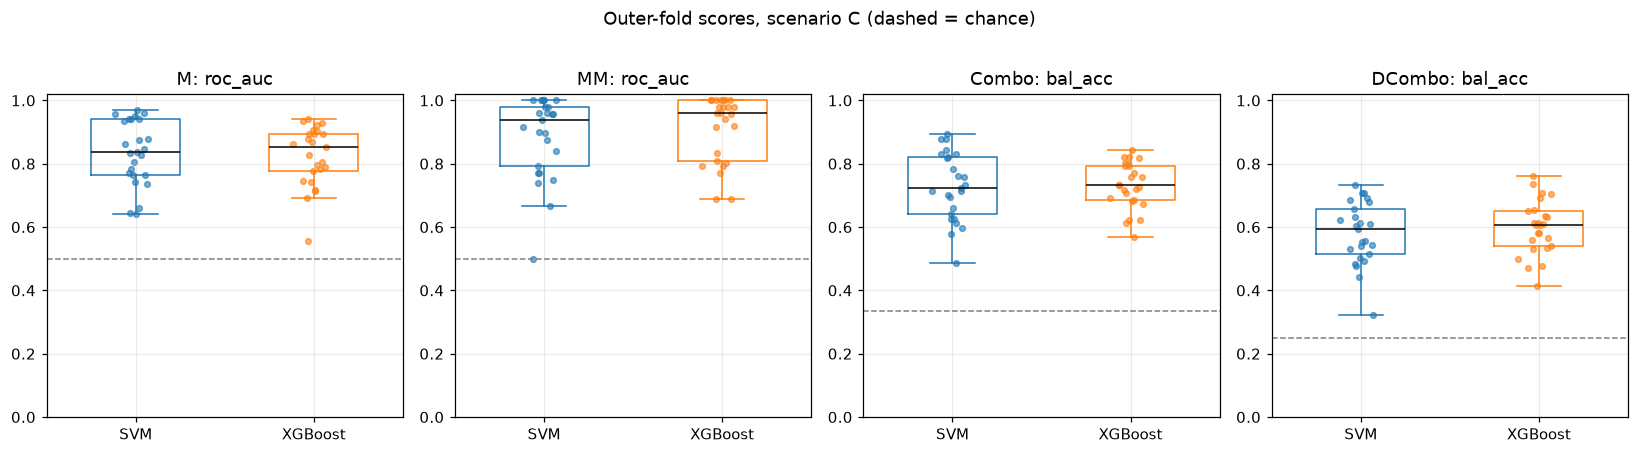

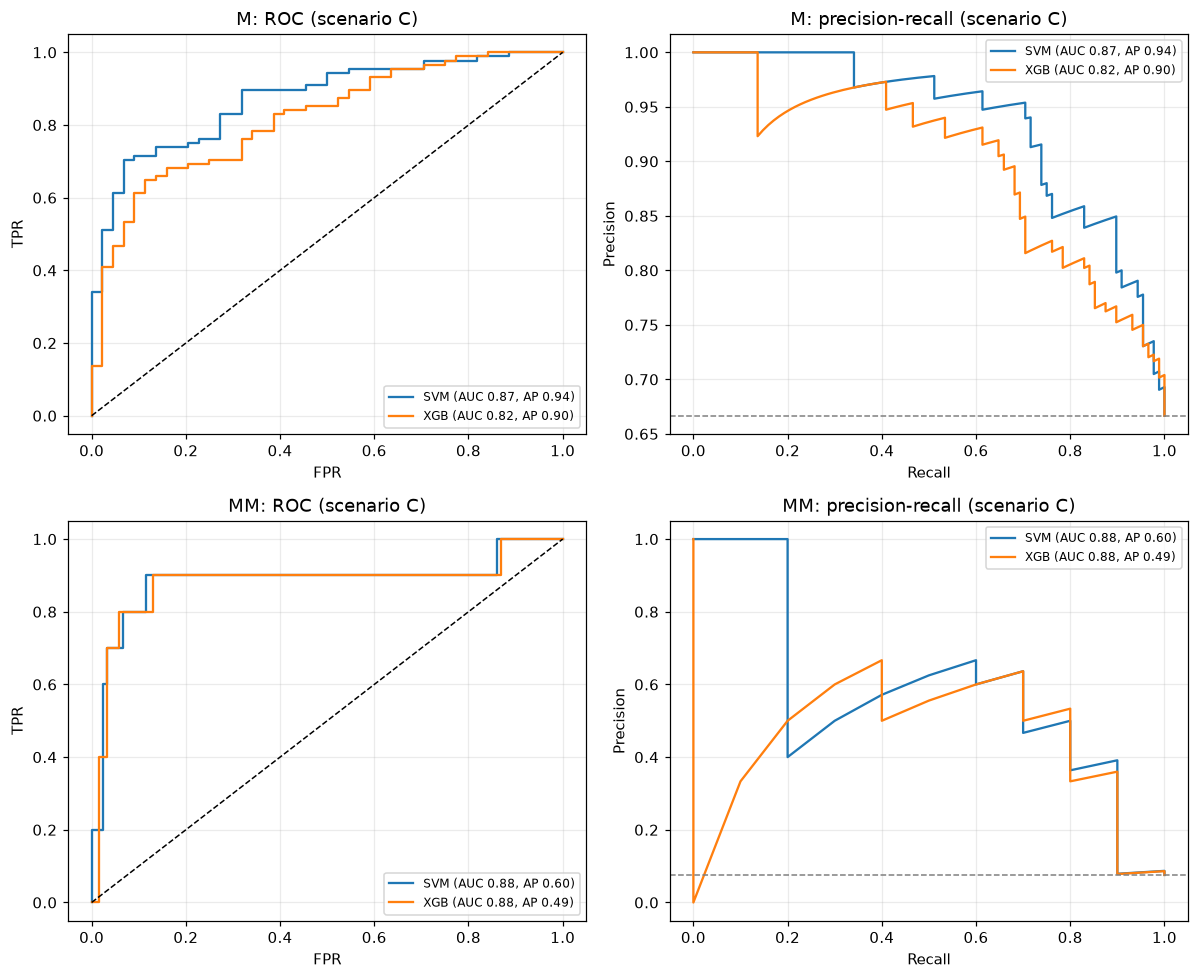

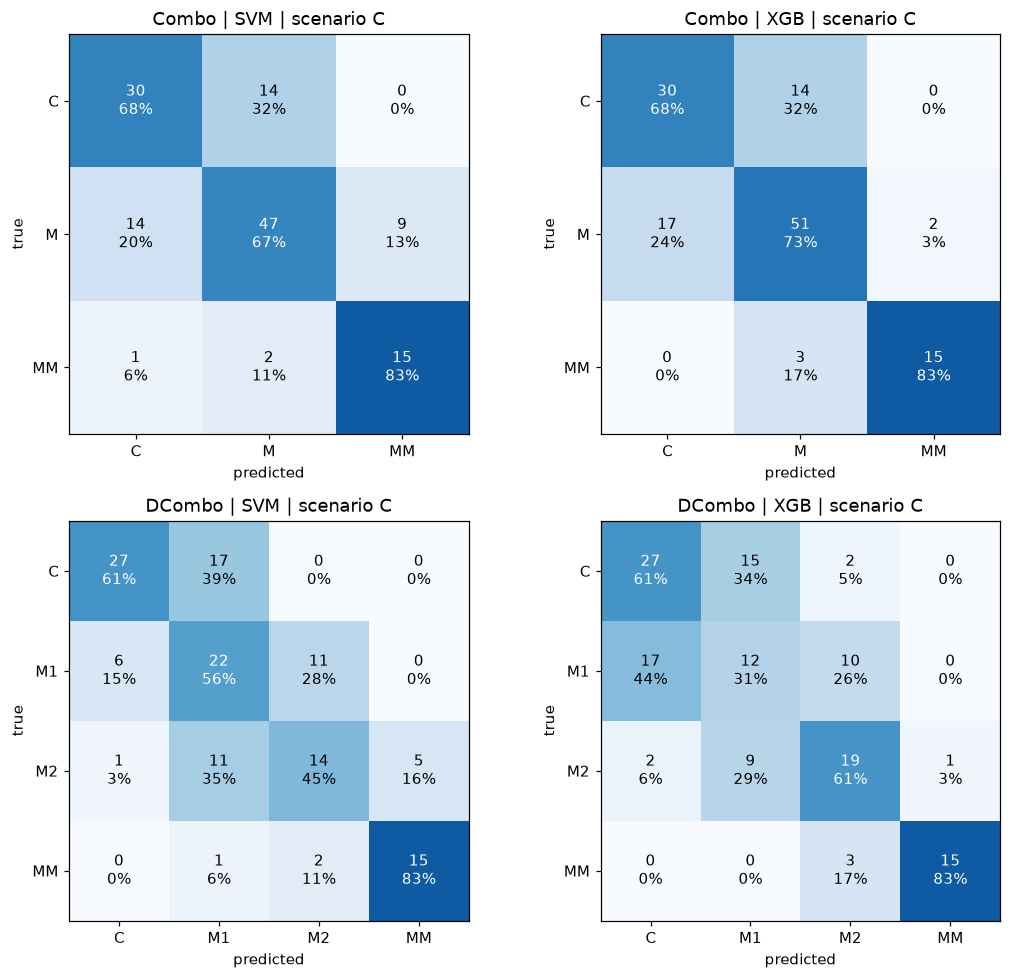

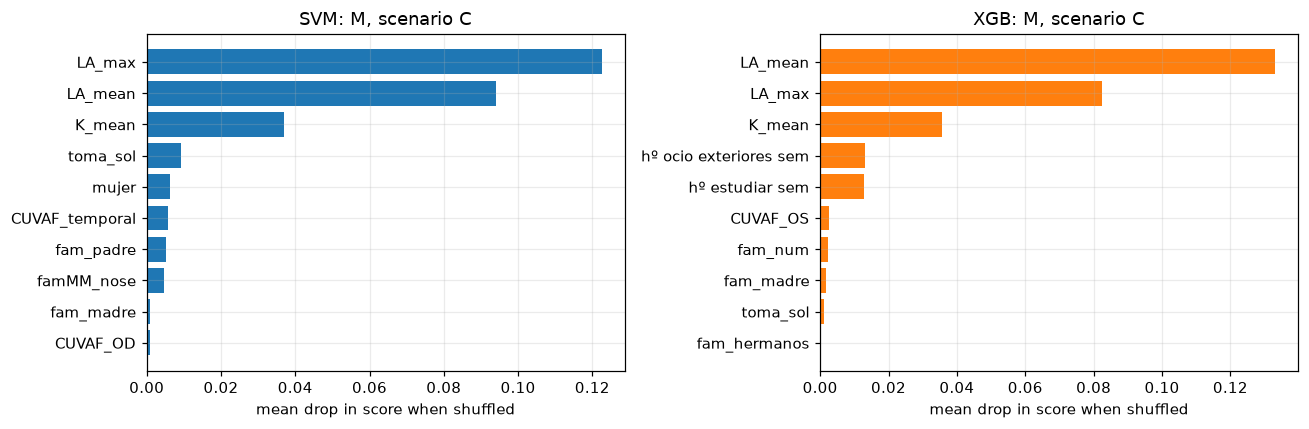

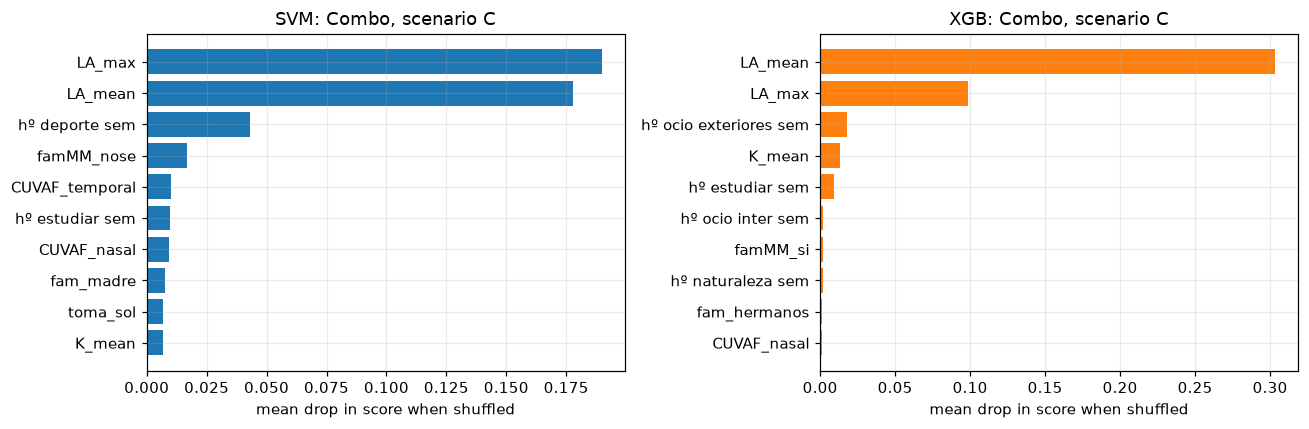


SVM, best params across outer folds (M, scenario C):
  svc__C {'100': 8, '0.01': 3, '0.1': 3, '10': 5, '1': 6}
  svc__gamma {'0.003': 8, '-': 8, '0.01': 5, '0.03': 4}
  svc__kernel {'rbf': 17, 'linear': 8}

XGB, best params across outer folds (M, scenario C):
  colsample_bytree {'0.5': 21, '1.0': 4}
  learning_rate {'0.03': 3, '0.1': 22}
  max_depth {'3': 2, '2': 20, '1': 3}
  min_child_weight {'3': 6, '1': 19}
  n_estimators {'200': 6, '100': 19}
  reg_lambda {'10': 13, '5': 7, '1': 5}
  subsample {'1.0': 8, '0.7': 17}
scenario      A_lifestyle  B_+CUVAF  C_+biometry
task   model                                    
Combo  SVM         0.4268    0.4376       0.7012
       XGB         0.3947    0.3953       0.7286
DCombo SVM         0.2834    0.3216       0.5680
       XGB         0.2778    0.2495       0.5926
M      SVM         0.4978    0.5363       0.8132
       XGB         0.7002    0.6996       0.7844
MM     SVM         0.1599    0.1662       0.4816
       XGB         0.0848    0.0

In [245]:
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})
COL = {'SVM': 'tab:blue', 'XGB': 'tab:orange'}
SCEN = 'C_+biometry'            # the only scenario shown; change this one line to look at A or B instead

# ---- Plot 1: fold-level scores, SVM vs XGBoost (scenario C) ----
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (t, (_, main)) in zip(axes, tasks.items()):
    for j, kind in enumerate(['SVM', 'XGB']):
        v = results[(t, SCEN, kind)]['scores'][main].values
        ax.boxplot(v, positions=[j], widths=.5, showfliers=False,
                   boxprops=dict(color=COL[kind]), medianprops=dict(color='k'),
                   whiskerprops=dict(color=COL[kind]), capprops=dict(color=COL[kind]))
        ax.scatter(np.random.default_rng(0).normal(j, .05, len(v)), v, s=14, color=COL[kind], alpha=.6)
    chance = {'roc_auc': .5, 'bal_acc': 1 / len(results[(t, SCEN, 'SVM')]['classes'])}[main]
    ax.axhline(chance, ls='--', c='gray', lw=1)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['SVM', 'XGBoost'])
    ax.set_title(f'{t}: {main}'); ax.set_ylim(0, 1.02)
plt.suptitle(f'Outer-fold scores, scenario {SCEN[0]} (dashed = chance)', y=1.02)
plt.tight_layout(); plt.show()

# ---- Plot 2: ROC and PR curves for M and MM (out-of-fold scores, scenario C) ----
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for r, t in enumerate(['M', 'MM']):
    for kind in ['SVM', 'XGB']:
        R = results[(t, SCEN, kind)]; y, p = R['y'], R['oof']
        fpr, tpr, _ = roc_curve(y, p); pr, rc, _ = precision_recall_curve(y, p)
        lab = f'{kind} (AUC {roc_auc_score(y, p):.2f}, AP {average_precision_score(y, p):.2f})'
        axes[r, 0].plot(fpr, tpr, c=COL[kind], label=lab)
        axes[r, 1].plot(rc, pr, c=COL[kind], label=lab)
    axes[r, 0].plot([0, 1], [0, 1], 'k--', lw=1); axes[r, 0].set_title(f'{t}: ROC (scenario {SCEN[0]})')
    axes[r, 0].set_xlabel('FPR'); axes[r, 0].set_ylabel('TPR')
    axes[r, 1].axhline((R['y'] == 1).mean(), c='gray', ls='--', lw=1); axes[r, 1].set_title(f'{t}: precision-recall (scenario {SCEN[0]})')
    axes[r, 1].set_xlabel('Recall'); axes[r, 1].set_ylabel('Precision')
    axes[r, 0].legend(fontsize=8, loc='lower right'); axes[r, 1].legend(fontsize=8, loc='upper right')
plt.tight_layout(); plt.show()

# ---- Plot 3: confusion matrices for Combo and DCombo (row-normalised, counts shown, scenario C) ----
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for r, t in enumerate(['Combo', 'DCombo']):
    for c, kind in enumerate(['SVM', 'XGB']):
        R = results[(t, SCEN, kind)]; cm = confusion_matrix(R['y'], R['oof'].argmax(1)); norm = cm / cm.sum(1, keepdims=True)
        ax = axes[r, c]; ax.imshow(norm, cmap='Blues', vmin=0, vmax=1); ax.grid(False)
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(j, i, f'{cm[i, j]}\n{norm[i, j]:.0%}', ha='center', va='center',
                        color='white' if norm[i, j] > .55 else 'black', fontsize=10)
        ax.set_xticks(range(len(R['classes']))); ax.set_xticklabels(R['classes'])
        ax.set_yticks(range(len(R['classes']))); ax.set_yticklabels(R['classes'])
        ax.set_title(f'{t} | {kind} | scenario {SCEN[0]}'); ax.set_xlabel('predicted'); ax.set_ylabel('true')
plt.tight_layout(); plt.show()

# ---- Plot 4: permutation importance on held-out folds (top 10, scenario C) ----
def importance_plot(task, scen, topn=10):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, kind in zip(axes, ['SVM', 'XGB']):
        imp = results[(task, scen, kind)]['importance'].sort_values().tail(topn)
        ax.barh(imp.index, imp.values, color=COL[kind]); ax.set_title(f'{kind}: {task}, scenario {scen[0]}')
        ax.set_xlabel('mean drop in score when shuffled')
    plt.tight_layout(); plt.show()
importance_plot('M', SCEN); importance_plot('Combo', SCEN)

# ---- Tuned hyperparameters: how stable are they across outer folds? (M, scenario C) ----
for kind in ['SVM', 'XGB']:
    plist = results[('M', SCEN, kind)]['params']
    print(f'\n{kind}, best params across outer folds (M, scenario {SCEN[0]}):')
    for k in sorted({k for p_ in plist for k in p_}):
        print(' ', k, dict(Counter(str(p_.get(k, '-')) for p_ in plist)))

# ---- F1 per task / model / scenario (positive-class F1 for M and MM, macro F1 for Combo and DCombo) ----
f1 = summ[summ.metric.isin(['f1', 'f1_macro'])]
print(f1.pivot(index=['task', 'model'], columns='scenario', values='mean').round(4))

We can see that the f1 score increases, in the majority of cases, sharply when using the scenario C

Now we prepare the test set. We apply the same `build_features` to `X_test`, so the test has the same 25 features. The `assert` checks that the columns are the same and in the same order as in the training set. Then we print how many NaN there are in the test: there are only a few, and the imputer inside each model fills them with the median of the training set.

In [246]:
F_test = build_features(X_test)
assert list(F_test.columns) == list(F.columns)
print(F_test.shape, '| NaNs per column:', F_test.isna().sum()[lambda s: s > 0].to_dict())

(24, 25) | NaNs per column: {'hº naturaleza sem': 2}


Here we train the final models with all the 132 students. In `chosen` we write, for each task, the model and the scenario that we decided from the results above.

`fit_final` does the tuning with a simple 5-fold CV over all the data and then trains the best model again on all the students. The "best CV score" that it prints is only for information: it is a little optimistic, because it was used to choose the hyperparameters. The honest score is the one from `nested_cv`.

Then we predict the labels of the 24 test students and save them in `preds`.

In [247]:
# Edit this dictionary with the model and scenario you decide to report for each task.
chosen = {'M':      ('SVM', 'C_+biometry'),
          'MM':     ('XGB', 'C_+biometry'),
          'Combo':  ('SVM', 'C_+biometry'),
          'DCombo': ('XGB', 'C_+biometry')}

def fit_final(y_raw, cols, kind, seed=0):
    le = LabelEncoder(); y = le.fit_transform(y_raw)
    scoring = 'roc_auc' if len(le.classes_) == 2 else 'balanced_accuracy'
    search = make_search(kind, scoring, StratifiedKFold(5, shuffle=True, random_state=seed), seed)
    Xf = F[cols].to_numpy(float)
    if kind == 'XGB': search.fit(Xf, y, sample_weight=compute_sample_weight('balanced', y))
    else:             search.fit(Xf, y)
    print(f'  best CV score {search.best_score_:.3f} | {search.best_params_}')
    return search, le

preds = pd.DataFrame(index=X_test.index)
for task, (kind, scen) in chosen.items():
    print(task, kind, scen)
    cols = scenarios[scen]
    search, le = fit_final(Y_t[task], cols, kind)
    preds[task] = le.inverse_transform(search.predict(F_test[cols].to_numpy(float)))

M SVM C_+biometry
  best CV score 0.906 | {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
MM XGB C_+biometry
  best CV score 0.934 | {'subsample': 1.0, 'reg_lambda': 1, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
Combo SVM C_+biometry
  best CV score 0.752 | {'svc__C': 10, 'svc__gamma': 0.003, 'svc__kernel': 'rbf'}
DCombo XGB C_+biometry
  best CV score 0.631 | {'subsample': 0.7, 'reg_lambda': 10, 'n_estimators': 100, 'min_child_weight': 1, 'max_depth': 1, 'learning_rate': 0.03, 'colsample_bytree': 0.5}


Each task has its own model, so the predictions can disagree. For example, a student can be M = NO but Combo = MM, which is impossible. Here we count how many test students have each type of contradiction.

In [248]:
bad = {
    'M=NO but Combo is M/MM':   ((preds['M'] == 'NO') & (preds['Combo'] != 'C')).sum(),
    'M=SI but Combo=C':         ((preds['M'] == 'SI') & (preds['Combo'] == 'C')).sum(),
    'MM=SI but Combo!=MM':      ((preds['MM'] == 'SI') & (preds['Combo'] != 'MM')).sum(),
    'Combo vs DCombo disagree': (preds['Combo'] != preds['DCombo'].replace({'M1': 'M', 'M2': 'M'})).sum(),
}
print('Contradictions between tasks:', bad)

Contradictions between tasks: {'M=NO but Combo is M/MM': np.int64(1), 'M=SI but Combo=C': np.int64(1), 'MM=SI but Combo!=MM': np.int64(1), 'Combo vs DCombo disagree': np.int64(8)}


To remove the contradictions, we build the final answer starting from Combo:
- **M** = SI if Combo is M or MM, and NO if Combo is C.
- **MM** = SI only if the MM model **and** the Combo model both say MM.
- **DCombo**: C and MM are copied from Combo. For the students that are M in Combo, a small SVM trained only on the myopic students (M1 and M2) chooses between M1 and M2.

At the end we check that there is one row per test student, in the same order as `X_test`, and we save the file `predictions_step1_svm_xgb.csv`.

In [249]:
cols = scenarios['C_+biometry']
myopes = Y_t['DCombo'].isin(['M1', 'M2'])
le12 = LabelEncoder(); y12 = le12.fit_transform(Y_t.loc[myopes, 'DCombo'])
search12 = make_search('SVM', 'roc_auc', StratifiedKFold(5, shuffle=True, random_state=0))
search12.fit(F.loc[myopes, cols].to_numpy(float), y12)

final = pd.DataFrame(index=X_test.index)
final['Combo'] = preds['Combo']
final['M'] = np.where(final['Combo'] == 'C', 'NO', 'SI')
final['MM'] = np.where((preds['MM'] == 'SI') & (final['Combo'] == 'MM'), 'SI', 'NO')   # SI only if both models agree
final['DCombo'] = final['Combo']                       # C and MM carry over unchanged
is_m = final['Combo'] == 'M'
if is_m.any():
    final.loc[is_m, 'DCombo'] = le12.inverse_transform(search12.predict(F_test.loc[is_m, cols].to_numpy(float)))
final = final[['M', 'MM', 'Combo', 'DCombo']]

final = final[list(Y_t.columns)]                  # same column names and order as the training labels: M, MM, Combo, DCombo
assert len(final) == len(X_test)                # one row per test student
assert list(final.index) == list(X_test.index)  # same row order as X_test (no sorting happened)

final.to_csv('predictions_step1_svm_xgb.csv', index=False)
print(pd.read_csv('predictions_step1_svm_xgb.csv').head())

    M  MM Combo DCombo
0  SI  SI    MM     MM
1  NO  NO     C      C
2  SI  SI    MM     MM
3  SI  NO     M     M1
4  SI  NO     M     M1


# Random Forest and Logistic Regression models

This part uses a different approach. We don't make our own features, we use almost all the original columns and a scikit-learn `ColumnTransformer` that prepares the numeric and the text columns automatically.

First we make a copy `X_rf` of the training data, so the first part of the notebook is not changed. We drop:
- `fecha`, because it is the date of the test and not information about the student.
- `origen antepasados (extranjeros)`, `Grupo fot` and `fototipo`, because they have many missing values.
- `origen antepasados (españa)`.

Then `sexo` and `fumador` are changed to 1/0.

In [250]:
# Work on a copy so X_t stays intact for the first part of the notebook.
# 'fecha' is the date of the test, not a property of the student, so it is dropped too.
X_rf = X_t.drop(columns=["fecha", "origen antepasados (extranjeros)", "Grupo fot", "fototipo",
                         "origen antepasados (españa)"])

X_rf["sexo"] = X_rf["sexo"].replace({'Mujer': 1, 'Hombre': 0})
X_rf["fumador"] = X_rf["fumador"].replace({'SI': 1, 'NO': 0})

X_rf.head()

,edad,sexo,hº deporte sem,hº naturaleza sem,hº ocio exteriores sem,horas exterior sem,hº estudiar sem,hº ocio inter sem,hº act.cerca sem,horas interior sem,...,OS-DS,CUVAF-Total,CUVAF-Media,CUVAF-DS,Promedio Nasal,DE Nasal,Suma Nasal,Promedio Temporal,DE Temporal,Suma Temporal
0,22,1,0.0,0.0,4.0,4.0,40,6,NaN,46.0,...,0.238059,2.256667,0.564167,0.842300,0.905000,1.279863,1.810000,0.223333,0.160278,0.446667
1,23,1,5.0,2.0,2.0,9.0,20,30,NaN,50.0,...,2.585654,8.026667,2.006667,1.887316,3.620833,0.503224,7.241667,0.392500,0.102530,0.785000
2,22,1,2.0,3.0,8.0,13.0,30,15,NaN,45.0,...,0.431335,12.710000,3.177500,0.743668,3.152500,1.248043,6.305000,3.202500,0.314663,6.405000
3,22,1,0.0,2.0,13.0,15.0,54,12,NaN,66.0,...,0.626968,3.551667,0.887917,0.877145,1.003333,1.418928,2.006667,0.772500,0.491439,1.545000
4,23,1,3.0,0.0,0.0,3.0,56,15,NaN,71.0,...,1.269257,1.795000,0.448750,0.897500,0.897500,1.269257,1.795000,0.000000,0.000000,0.000000


We print the type of each column. Numbers are `int64` or `float64`. Text columns (like `familiar miope` or `toma sol`) are `object` or `str`, and they must be encoded before we use them in a model.

In [251]:

# Check how pandas treats each column
print(X_rf.dtypes)


edad                        int64
sexo                       object
hº deporte sem            float64
hº naturaleza sem         float64
hº ocio exteriores sem    float64
horas exterior sem        float64
hº estudiar sem             int64
hº ocio inter sem           int64
hº act.cerca sem          float64
horas interior sem        float64
Ratio Cerca/Lejos         float64
Exterior Mucho                str
Interior Mcho                 str
familiar miope                str
Familiar miope num.       float64
Familiar MM SI/NO             str
familiar miope magno          str
pat. Ret. Miop magna          str
fumador                    object
toma sol                      str
protege sol                   str
disp.elec.antes dormir        str
LA OD                     float64
LA OS                     float64
LA Media                  float64
Querato OD                float64
Querato OD Eje2           float64
Querato OS                float64
Querato OS Eje 2          float64
OD-Total      

For every numeric column we print how many different values it has. Columns with 2 values are binary, columns with few values are like categories or levels, and columns with many values are continuous.

In [252]:
# Check how many unique values each numerical column has to identify binary/ordinal variables
num_features = X_rf.select_dtypes(include=['int64', 'float64']).columns.tolist()
print(X_rf[num_features].nunique())


edad                        6
hº deporte sem             17
hº naturaleza sem          13
hº ocio exteriores sem     17
horas exterior sem         32
hº estudiar sem            37
hº ocio inter sem          31
hº act.cerca sem            0
horas interior sem         60
Ratio Cerca/Lejos         111
Familiar miope num.         3
LA OD                     107
LA OS                     115
LA Media                  123
Querato OD                 73
Querato OD Eje2            79
Querato OS                 78
Querato OS Eje 2           75
OD-Total                  113
OD-Media                  113
OD-DS                     113
OS-Total                  121
OS-Media                  121
OS-DS                     117
CUVAF-Total               123
CUVAF-Media               123
CUVAF-DS                  124
Promedio Nasal            118
DE Nasal                  112
Suma Nasal                118
Promedio Temporal         107
DE Temporal               105
Suma Temporal             107
dtype: int

Percentage of missing values per column after the drops. Most of the columns have 0% or very few. `hº act.cerca sem` is still 100% empty: the imputer can not fill it, so it skips this column and shows a warning (this is not a problem).

In [253]:

print(X_rf.isnull().mean() * 100) # This gives the exact percentage of null values per column


edad                        0.000000
sexo                        0.000000
hº deporte sem              0.000000
hº naturaleza sem           0.000000
hº ocio exteriores sem      1.515152
horas exterior sem          0.000000
hº estudiar sem             0.000000
hº ocio inter sem           0.000000
hº act.cerca sem          100.000000
horas interior sem          0.757576
Ratio Cerca/Lejos           0.000000
Exterior Mucho              0.000000
Interior Mcho               0.000000
familiar miope              0.757576
Familiar miope num.         3.030303
Familiar MM SI/NO           0.000000
familiar miope magno        0.000000
pat. Ret. Miop magna        1.515152
fumador                     0.000000
toma sol                    0.000000
protege sol                 0.000000
disp.elec.antes dormir      0.000000
LA OD                       0.000000
LA OS                       0.000000
LA Media                    0.000000
Querato OD                  0.000000
Querato OD Eje2             0.000000
Q

Imports for the preprocessing of this part.

In [254]:

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


We make two lists: `num_features` with the numeric columns and `cat_features` with the text columns. Each list will be prepared in a different way.

In [255]:

# 1. Separation of columns according to their actual dtypes
num_features = X_rf.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X_rf.select_dtypes(include=['object']).columns.tolist()


/var/folders/j_/csb44tdj46q5z7vld9q7xss80000gn/T/ipykernel_57961/2452223546.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = X_rf.select_dtypes(include=['object']).columns.tolist()


For the numeric columns: first we fill the holes with the median of the column, then we scale them (mean 0 and standard deviation 1). The scaling is important for Logistic Regression. Random Forest doesn't need it, but it doesn't hurt.

In [256]:

# 2. Pipeline for numerical variables (Imputation by median + Scaling)
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


For the text columns: first we fill the holes with the most frequent value, then we use one-hot encoding (one 0/1 column for each category). With `handle_unknown='ignore'`, if the test has a category that the training set doesn't have, all its columns are 0 and there is no error.

In [257]:

# 3. Pipeline for categorical variables (Imputation by mode + One-Hot Encoding)
cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])


The `ColumnTransformer` joins the two pipelines: it sends each column to the correct one. Here we run it once only to check that it works and to see the final shape (students x columns after the one-hot encoding). Inside the models it is fitted again every time.

In [258]:

# 4. Global column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_features),
        ('cat', cat_pipeline, cat_features)
    ]
)

# We try to transform X_rf to verify that everything works without errors
X_t_prepared = preprocessor.fit_transform(X_rf) 
print("Prepared shape:", X_t_prepared.shape)


Prepared shape: (132, 70)


/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


## Target M (myopia yes/no)

In [259]:

"""Y = "M"
"""


'Y = "M"\n'

We take the M column as target and we look at the balance of the classes: around 2/3 of the students are SI.

In [260]:
# Selecting M column
y_t1 = Y_t['M']

In [261]:
# Number of cases and percentage by class
print("Absolute count by class:")
print(y_t1.value_counts())
print("\nPercentage by class:")
print(y_t1.value_counts(normalize=True) * 100)

Absolute count by class:
M
SI    88
NO    44
Name: count, dtype: int64

Percentage by class:
M
SI    66.666667
NO    33.333333
Name: proportion, dtype: float64


**Random Forest for M.** The pipeline joins the preprocessing and the classifier, so the same steps are applied to the training and the test data. `class_weight='balanced'` gives more weight to the small class. The model is trained with all the training students and the default hyperparameters.

In [262]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Global pipeline: Preprocessing + Classifier
pipeline_random_M = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced'))
])

# Training the pipeline with X_rf and y_t
pipeline_random_M.fit(X_rf, y_t1)
print("Random Forest pipeline for M trained successfully!")

Random Forest pipeline for M trained successfully!


/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


**Logistic Regression for M**, with the same preprocessing. `max_iter=1000` gives the algorithm more steps to converge.

In [263]:
from sklearn.linear_model import LogisticRegression

# Pipeline for Logistic Regression
pipeline_logreg_M = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000))
])

# training the pipeline with X_rf and y_t
pipeline_logreg_M.fit(X_rf, y_t1)

print("Logistic Regression pipeline for M trained successfully!")

Logistic Regression pipeline for M trained successfully!


/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


## Target MM (myopia magna yes/no)

In [264]:
"""Y = "MM"
"""

'Y = "MM"\n'

We take the MM column as target. Only 10 of the 132 students are SI (around 7.6%), so this target is very unbalanced.

In [265]:
# Selecting the 'MM' column
y_t2 = Y_t['MM']

# See the number of cases and percentage by class
print("Absolute count by class:")
print(y_t2.value_counts())
print("\nPercentage by class:")
print(y_t2.value_counts(normalize=True) * 100)

Absolute count by class:
MM
NO    122
SI     10
Name: count, dtype: int64

Percentage by class:
MM
NO    92.424242
SI     7.575758
Name: proportion, dtype: float64


We define the Random Forest pipeline for MM (same as for M).

In [266]:
# Global pipeline: Preprocessing + Classifier
pipeline_random_MM = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced'))
])

And we train it with all the training students.

In [267]:

# Training the pipeline with X_rf and y_t
pipeline_random_MM.fit(X_rf, y_t2)
print("Random Forest pipeline for MM trained successfully!")


/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Random Forest pipeline for MM trained successfully!


Logistic Regression for MM, defined and trained in the same cell.

In [268]:

# Global pipeline: Preprocessing + Logistic Regression
pipeline_logreg_MM = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000))
])

# Training the pipeline with X_rf and y_t
pipeline_logreg_MM.fit(X_rf, y_t2)

print("Logistic Regression pipeline for MM trained successfully!")

/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Logistic Regression pipeline for MM trained successfully!


## Target Combo (C / M / MM)

In [269]:
"""Y = "Combo"
"""

'Y = "Combo"\n'

We take the Combo column as target and look at the three classes: M is the biggest, MM is the smallest.

In [270]:
# Selecting the 'Combo' column
y_t3 = Y_t['Combo']

# Number of cases and percentage by class
print("Absolute count by class:")
print(y_t3.value_counts())
print("\nPercentage by class:")
print(y_t3.value_counts(normalize=True) * 100)


Absolute count by class:
Combo
M     70
C     44
MM    18
Name: count, dtype: int64

Percentage by class:
Combo
M     53.030303
C     33.333333
MM    13.636364
Name: proportion, dtype: float64


Random Forest for Combo. It works with three classes directly, nothing changes in the code.

In [271]:

# Global pipeline: Preprocessing + Classifier
pipeline_random_Combo = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced'))
])

# Training the complete pipeline with X_rf and y_t
pipeline_random_Combo.fit(X_rf, y_t3)
print("Random Forest pipeline for Combo trained successfully!")


Random Forest pipeline for Combo trained successfully!


/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Logistic Regression for Combo. With three classes it learns one set of weights for each class.

In [272]:

# Global pipeline: Preprocessing + Logistic Regression
pipeline_logreg_Combo = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000))
])

# Training the pipeline with X_rf and y_t
pipeline_logreg_Combo.fit(X_rf, y_t3)

print("Logistic Regression pipeline for Combo trained successfully!")


Logistic Regression pipeline for Combo trained successfully!


/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


A quick look at the targets again before the last one.

In [273]:

Y_t.head()


,M,MM,Combo,DCombo
0,SI,SI,MM,MM
1,SI,NO,M,M1
2,NO,NO,C,C
3,NO,NO,C,C
4,NO,NO,C,C


## Target DCombo (C / M1 / M2 / MM)

In [274]:

"""**Y** = DCombo"""


'**Y** = DCombo'

We take the DCombo column as target.

In [275]:

# Select the 'DCombo' column
y_t4 = Y_t['DCombo']


The four classes are more balanced than in MM, but M1 and M2 are similar students, so this task is the most difficult one.

In [276]:

# Show number of cases and percentage by class
print("Absolute count by class:")
print(y_t4.value_counts())
print("\nPercentage by class:")
print(y_t4.value_counts(normalize=True) * 100)


Absolute count by class:
DCombo
C     44
M1    39
M2    31
MM    18
Name: count, dtype: int64

Percentage by class:
DCombo
C     33.333333
M1    29.545455
M2    23.484848
MM    13.636364
Name: proportion, dtype: float64


Random Forest for DCombo.

In [277]:

# Global pipeline: Preprocessing + Classifier
pipeline_random_DCombo = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced'))
])

# Training the complete pipeline with X_rf and y_t
pipeline_random_DCombo.fit(X_rf, y_t4)
print("Random Forest pipeline for DCombo trained successfully!")


/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Random Forest pipeline for DCombo trained successfully!


Logistic Regression for DCombo.

In [278]:

# Global pipeline: Preprocessing + Logistic Regression
pipeline_logreg_DCombo = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000))
])

# Training the pipeline with X_rf and y_t
pipeline_logreg_DCombo.fit(X_rf, y_t4)

print("Logistic Regression pipeline for DCombo trained successfully!")


Logistic Regression pipeline for DCombo trained successfully!


/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Now we evaluate RF and LR for each target with 5-fold cross-validation and the macro F1 score. For each target the cell prints the mean F1 of the two models.

Note: this is a simple CV with the default hyperparameters, not the nested CV of the first part. So these numbers can not be compared directly with the SVM and XGBoost numbers. That is why at the end of the notebook we compare the four models in the same way.

At the end of the cell we also prepare the test set: we keep the same columns as `X_rf` and we change `sexo` and `fumador` to 1/0, like in the training data.

In [279]:

from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Associating target variables in a dictionary for iteration
targets = {
    'M (y_t1)': y_t1,
    'MM (y_t2)': y_t2,
    'Combo (y_t3)': y_t3,
    'DCombo (y_t4)': y_t4
}

# We use cross-validation to evaluate the models and print the average F1-score for each target variable
for nombre, y_target in targets.items():
    print(f"=================== {nombre} ===================")

    # --- Random Forest ---
    rf_pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced'))
    ])
    scores_rf = cross_val_score(rf_pipe, X_rf, y_target, cv=5, scoring='f1_macro')
    print(f"Random Forest     - F1-Score mean: {scores_rf.mean():.4f}")

    # --- Logistical Regression ---
    lr_pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000))
    ])
    scores_lr = cross_val_score(lr_pipe, X_rf, y_target, cv=5, scoring='f1_macro')
    print(f"Logistic Regression - F1-Score mean: {scores_lr.mean():.4f}\n")

X_test = pd.read_csv('data/X_test.csv')

cols_a_conservar = X_rf.columns
X_test_clean = X_test[cols_a_conservar].copy()
X_test_clean["sexo"] = X_test_clean["sexo"].replace({'Mujer': 1, 'Hombre': 0})
X_test_clean["fumador"] = X_test_clean["fumador"].replace({'SI': 1, 'NO': 0})


=================== M (y_t1) ===================


/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing valu

Random Forest     - F1-Score mean: 0.7130
Logistic Regression - F1-Score mean: 0.7638

=================== MM (y_t2) ===================


/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing valu

Random Forest     - F1-Score mean: 0.5283
Logistic Regression - F1-Score mean: 0.7075

=================== Combo (y_t3) ===================


/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing valu

Random Forest     - F1-Score mean: 0.6880
Logistic Regression - F1-Score mean: 0.6664

=================== DCombo (y_t4) ===================


/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing valu

Random Forest     - F1-Score mean: 0.6059
Logistic Regression - F1-Score mean: 0.5729



We predict the 24 test students with the model that won in the CV above for each target (Logistic Regression for M, MM and DCombo, Random Forest for Combo).

In [280]:

# Create an empty DataFrame to store predictions
Y_pred = pd.DataFrame(index=X_test.index)

# Predictions for each target variable using the best model identified in cross-validation
Y_pred['M'] = pipeline_logreg_M.predict(X_test_clean)       # Winner M
Y_pred['MM'] = pipeline_logreg_MM.predict(X_test_clean)     # Winner MM
Y_pred['Combo'] = pipeline_random_Combo.predict(X_test_clean) # Winner Combo
Y_pred['DCombo'] = pipeline_logreg_DCombo.predict(X_test_clean) # Winner DCombo


/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/alex/src/ML-Miopia/.ML/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['hº act.cerca sem']. At least one non-missing valu

We save these predictions in `predictions_step2_rf_logreg.csv` and we show the first rows.

In [281]:

# Save the predictions in a CSV file for submission
Y_pred.to_csv('predictions_step2_rf_logreg.csv', index=False)

print("Predictions saved to 'predictions_step2_rf_logreg.csv' successfully!")
Y_pred.head()


Predictions saved to 'predictions_step2_rf_logreg.csv' successfully!


,M,MM,Combo,DCombo
0,SI,NO,MM,MM
1,NO,NO,C,C
2,SI,SI,MM,MM
3,SI,NO,M,M1
4,SI,NO,M,M1


Here we compare the percentage of each class in the test predictions with the percentage in the training labels. If they are very different it can be a sign of a problem, but the test has only 24 students, so some difference is normal.

In [282]:

# Checking the distribution of answers for each variable in the predictions
for col in Y_pred.columns:
    print(f"=== Distribution of Predictions for {col} ===")
    print(Y_pred[col].value_counts(normalize=True) * 100)
    print("\n")

for col in Y_t.columns:
  print(f"=== Distribution of Predictions for {col} ===")
  print(Y_t[col].value_counts(normalize=True) * 100)
  print("\n")

=== Distribution of Predictions for M ===
M
SI    62.5
NO    37.5
Name: proportion, dtype: float64


=== Distribution of Predictions for MM ===
MM
NO    83.333333
SI    16.666667
Name: proportion, dtype: float64


=== Distribution of Predictions for Combo ===
Combo
C     41.666667
M     37.500000
MM    20.833333
Name: proportion, dtype: float64


=== Distribution of Predictions for DCombo ===
DCombo
C     37.500000
M1    25.000000
MM    20.833333
M2    16.666667
Name: proportion, dtype: float64


=== Distribution of Predictions for M ===
M
SI    66.666667
NO    33.333333
Name: proportion, dtype: float64


=== Distribution of Predictions for MM ===
MM
NO    92.424242
SI     7.575758
Name: proportion, dtype: float64


=== Distribution of Predictions for Combo ===
Combo
M     53.030303
C     33.333333
MM    13.636364
Name: proportion, dtype: float64


=== Distribution of Predictions for DCombo ===
DCombo
C     33.333333
M1    29.545455
M2    23.484848
MM    13.636364
Name: proportion, dty

# Comparing the four models

SVM and XGBoost were already evaluated with nested cross-validation. To compare them fairly with Random Forest and Logistic Regression, we run RF and LR through the same `nested_cv` (same folds, same features from scenario C, same metrics).

For each target we keep the model with the highest **balanced accuracy**: it scores the final labels (which is what we hand in) and it is not fooled by the imbalance in MM.

What this cell does:
1. It runs `nested_cv` for Random Forest and Logistic Regression on the four tasks with scenario C (SVM and XGBoost are already in `results`). This takes some minutes.
2. It prints one table per task with the mean of every metric for the four models, and `bal_acc_std`, the standard deviation of the balanced accuracy between folds.
3. It chooses the best model for each task (`best_model`) and prints it.
4. It makes a boxplot of the balanced accuracy per fold for the four models. The dashed line is chance level.

If two models are very close (the difference is smaller than the standard deviation), they are practically equal, and the winner can change if we run again with other folds.

M       C_+biometry  RF     83s
M       C_+biometry  LR     86s
MM      C_+biometry  RF    172s
MM      C_+biometry  LR    176s
Combo   C_+biometry  RF    260s
Combo   C_+biometry  LR    263s
DCombo  C_+biometry  RF    346s
DCombo  C_+biometry  LR    350s

M
       roc_auc  pr_auc  bal_acc     f1  bal_acc_std
model                                              
SVM      0.835   0.922    0.753  0.813        0.095
XGB      0.825   0.913    0.733  0.784        0.091
RF       0.827   0.919    0.712  0.772        0.070
LR       0.853   0.933    0.755  0.815        0.111

MM
       roc_auc  pr_auc  bal_acc     f1  bal_acc_std
model                                              
SVM      0.886   0.640    0.736  0.482        0.163
XGB      0.910   0.662    0.814  0.549        0.170
RF       0.910   0.549    0.667  0.347        0.159
LR       0.881   0.595    0.826  0.509        0.143

Combo
       bal_acc  bal_acc_std  f1_macro
model                                
SVM      0.728        0.107   

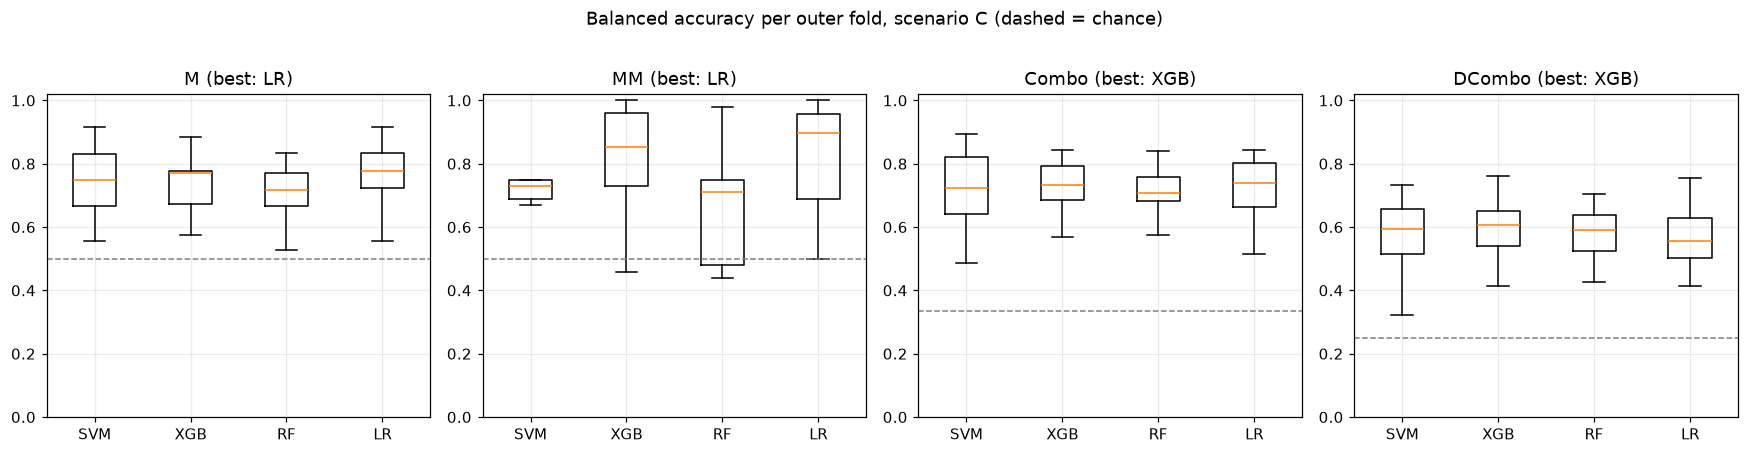

In [283]:
SCEN = 'C_+biometry'
MODELS = ['SVM', 'XGB', 'RF', 'LR']

t0 = time.time()
for t, (yy, _) in tasks.items():
    for kind in ['RF', 'LR']:                   # SVM and XGB are already in `results`
        results[(t, SCEN, kind)] = nested_cv(yy, scenarios[SCEN], kind, n_repeats=5)
        print(f'{t:7s} {SCEN:12s} {kind}  {time.time()-t0:5.0f}s', flush=True)

comp = pd.DataFrame([{'task': t, 'model': k, **results[(t, SCEN, k)]['scores'].mean(),
                      'bal_acc_std': results[(t, SCEN, k)]['scores']['bal_acc'].std()}
                     for t in tasks for k in MODELS])
for t in tasks:
    print(f'\n{t}')
    print(comp[comp.task == t].drop(columns='task').dropna(axis=1).set_index('model').round(3))

best_model = comp.loc[comp.groupby('task')['bal_acc'].idxmax()].set_index('task')['model']
print('\nBest model per target (balanced accuracy):', best_model.to_dict())

# Balanced accuracy per outer fold, all four models
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, t in zip(axes, tasks):
    v = [results[(t, SCEN, k)]['scores']['bal_acc'].values for k in MODELS]
    ax.boxplot(v, showfliers=False)
    ax.set_xticks(range(1, len(MODELS) + 1)); ax.set_xticklabels(MODELS)
    ax.axhline(1 / len(results[(t, SCEN, 'SVM')]['classes']), ls='--', c='gray', lw=1)
    ax.set_title(f'{t} (best: {best_model[t]})'); ax.set_ylim(0, 1.02)
plt.suptitle(f'Balanced accuracy per outer fold, scenario {SCEN[0]} (dashed = chance)', y=1.02)
plt.tight_layout(); plt.show()

Final predictions: each target is predicted by its best model, refitted (with tuning) on the full training set.

For each target we take the best model, we tune it and train it again with all the training students (`fit_final`), and we predict the test students. Then we count the contradictions between the four columns, like before, and we save the result in `predictions_step3_best_model.csv`.

Note: here each column comes from a different model, so some contradictions can appear (for example M = SI but Combo = C). If we want answers that always agree, we can apply the same correction that we used for `predictions_step1_svm_xgb.csv`.

In [284]:
best_final = pd.DataFrame(index=X_test.index)
for task in Y_t.columns:                         # M, MM, Combo, DCombo
    kind = best_model[task]
    print(task, kind, SCEN)
    search, le = fit_final(Y_t[task], scenarios[SCEN], kind)
    best_final[task] = le.inverse_transform(search.predict(F_test[scenarios[SCEN]].to_numpy(float)))

# The four targets are predicted independently, so check whether they contradict each other
bad = {
    'M=NO but Combo is M/MM':   ((best_final['M'] == 'NO') & (best_final['Combo'] != 'C')).sum(),
    'M=SI but Combo=C':         ((best_final['M'] == 'SI') & (best_final['Combo'] == 'C')).sum(),
    'MM=SI but Combo!=MM':      ((best_final['MM'] == 'SI') & (best_final['Combo'] != 'MM')).sum(),
    'Combo vs DCombo disagree': (best_final['Combo'] != best_final['DCombo'].replace({'M1': 'M', 'M2': 'M'})).sum(),
}
print('Contradictions between tasks:', bad)

assert list(best_final.index) == list(X_test.index)
best_final.to_csv('predictions_step3_best_model.csv', index=False)
print(pd.read_csv('predictions_step3_best_model.csv').head())

M LR C_+biometry
  best CV score 0.893 | {'logisticregression__C': 1}
MM LR C_+biometry
  best CV score 0.921 | {'logisticregression__C': 10}
Combo XGB C_+biometry
  best CV score 0.743 | {'subsample': 1.0, 'reg_lambda': 1, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 2, 'learning_rate': 0.1, 'colsample_bytree': 0.5}
DCombo XGB C_+biometry
  best CV score 0.631 | {'subsample': 0.7, 'reg_lambda': 10, 'n_estimators': 100, 'min_child_weight': 1, 'max_depth': 1, 'learning_rate': 0.03, 'colsample_bytree': 0.5}
Contradictions between tasks: {'M=NO but Combo is M/MM': np.int64(1), 'M=SI but Combo=C': np.int64(3), 'MM=SI but Combo!=MM': np.int64(1), 'Combo vs DCombo disagree': np.int64(7)}
    M  MM Combo DCombo
0  SI  NO    MM     MM
1  NO  NO     C     M1
2  SI  SI    MM     MM
3  SI  NO     M     M1
4  SI  NO     M      C
